# Practical Assignment 5: Ensemble Learning and Performance Evaluation

| | |
|---|---|
| **Name** | Yash Galande |
| **PRN / Roll No.** | 202401040179 |
| **Division / Batch** | A2 – 41 |
| **Subject** | AIML |
| **Due** | 27 October 2026, 8:00 AM |

**Objectives**
1. Implement a **Stacking** ensemble with a meta-classifier
2. Implement an **AdaBoost** ensemble
3. Implement a **Voting** ensemble (majority / hard voting, plus soft voting)
4. Compare ensembles with base models using classification metrics
5. Summarise findings, when to use each method, and future improvements

## 🔗 Google Colab & GitHub Links

- **Google Colab notebook:** [Open in Colab](PASTE_YOUR_COLAB_LINK_HERE)
  (Upload this `.ipynb` to Colab → *Share* → set to *Anyone with the link can view* → paste the link above)
- **GitHub repository:** [PASTE_YOUR_GITHUB_LINK_HERE](PASTE_YOUR_GITHUB_LINK_HERE)
  (Create a repo, e.g. `AIML-Practical-5-Ensemble-Learning`, upload this notebook, paste the repo URL above)

> Tip: in Colab you can also use *File → Save a copy in GitHub* to push the notebook directly.

## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

from sklearn.ensemble import VotingClassifier, StackingClassifier, AdaBoostClassifier

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve, classification_report)

sns.set_style('whitegrid')
RANDOM_STATE = 42

## 2. Load and Explore the Dataset
We use the **Breast Cancer Wisconsin (Diagnostic)** dataset (built into scikit-learn, so no upload is needed in Colab). It is a binary classification problem: malignant (0) vs benign (1).

In [2]:
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name='target')

print('Shape:', X.shape)
print('Classes:', dict(zip(data.target_names, np.bincount(y))))
print('Missing values:', X.isnull().sum().sum())
X.head()

Shape: (569, 30)
Classes: {np.str_('malignant'): np.int64(212), np.str_('benign'): np.int64(357)}
Missing values: 0


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


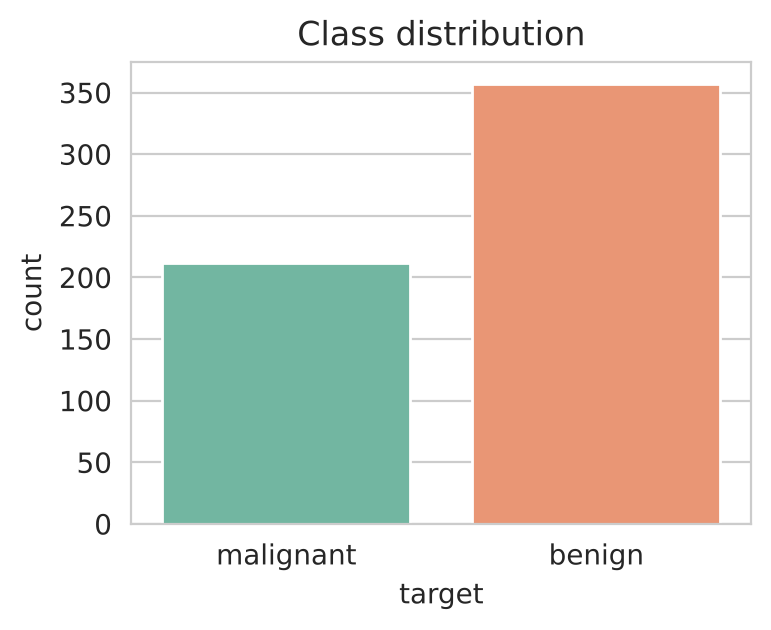

In [3]:
plt.figure(figsize=(4,3))
sns.countplot(x=y.map({0:'malignant',1:'benign'}), palette='Set2')
plt.title('Class distribution'); plt.show()

## 3. Train/Test Split

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape)

(455, 30) (114, 30)


## 4. Base Classifiers
Distance/margin-based models (LR, KNN, SVM) need feature scaling, so they are wrapped in pipelines with `StandardScaler`. Five diverse base learners are used so the ensembles have different "opinions" to combine.

In [5]:
def base_models():
    return {
        'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
        'KNN':                 make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7)),
        'Decision Tree':       DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
        'SVM (RBF)':           make_pipeline(StandardScaler(), SVC(kernel='rbf', probability=True, random_state=RANDOM_STATE)),
        'Naive Bayes':         GaussianNB(),
    }

models = base_models()
for name, m in models.items():
    m.fit(X_train, y_train)
    print(f'{name:22s} test accuracy = {m.score(X_test, y_test):.4f}')

Logistic Regression    test accuracy = 0.9825
KNN                    test accuracy = 0.9737
Decision Tree          test accuracy = 0.9211


SVM (RBF)              test accuracy = 0.9825
Naive Bayes            test accuracy = 0.9386


## 5. Voting Ensemble
- **Hard voting** = majority vote of predicted class labels (as required by the assignment)
- **Soft voting** = average of predicted probabilities (added for comparison)

In [6]:
estimators = list(base_models().items())

voting_hard = VotingClassifier(estimators=estimators, voting='hard')
voting_soft = VotingClassifier(estimators=estimators, voting='soft')

voting_hard.fit(X_train, y_train)
voting_soft.fit(X_train, y_train)

print('Hard Voting accuracy:', round(voting_hard.score(X_test, y_test), 4))
print('Soft Voting accuracy:', round(voting_soft.score(X_test, y_test), 4))

Hard Voting accuracy: 0.9737
Soft Voting accuracy: 0.9737


## 6. Stacking Ensemble
Base classifiers produce out-of-fold predictions (5-fold CV) which become the input features of a **meta-classifier** (Logistic Regression) that learns how best to combine them.

In [7]:
stacking = StackingClassifier(
    estimators=list(base_models().items()),
    final_estimator=LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    cv=5, stack_method='predict_proba', passthrough=False)

stacking.fit(X_train, y_train)
print('Stacking accuracy:', round(stacking.score(X_test, y_test), 4))

Stacking accuracy: 0.9737


## 7. AdaBoost Ensemble
AdaBoost trains weak learners sequentially, increasing the weights of misclassified samples. We try two base learners: a **decision stump** (depth 1) and a **depth-3 tree**.

In [8]:
ada_stump = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1),
                               n_estimators=200, learning_rate=0.5, random_state=RANDOM_STATE)
ada_tree3 = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=3),
                               n_estimators=100, learning_rate=0.5, random_state=RANDOM_STATE)

ada_stump.fit(X_train, y_train)
ada_tree3.fit(X_train, y_train)
print('AdaBoost (stump)   accuracy:', round(ada_stump.score(X_test, y_test), 4))
print('AdaBoost (depth 3) accuracy:', round(ada_tree3.score(X_test, y_test), 4))

AdaBoost (stump)   accuracy: 0.9561
AdaBoost (depth 3) accuracy: 0.9649


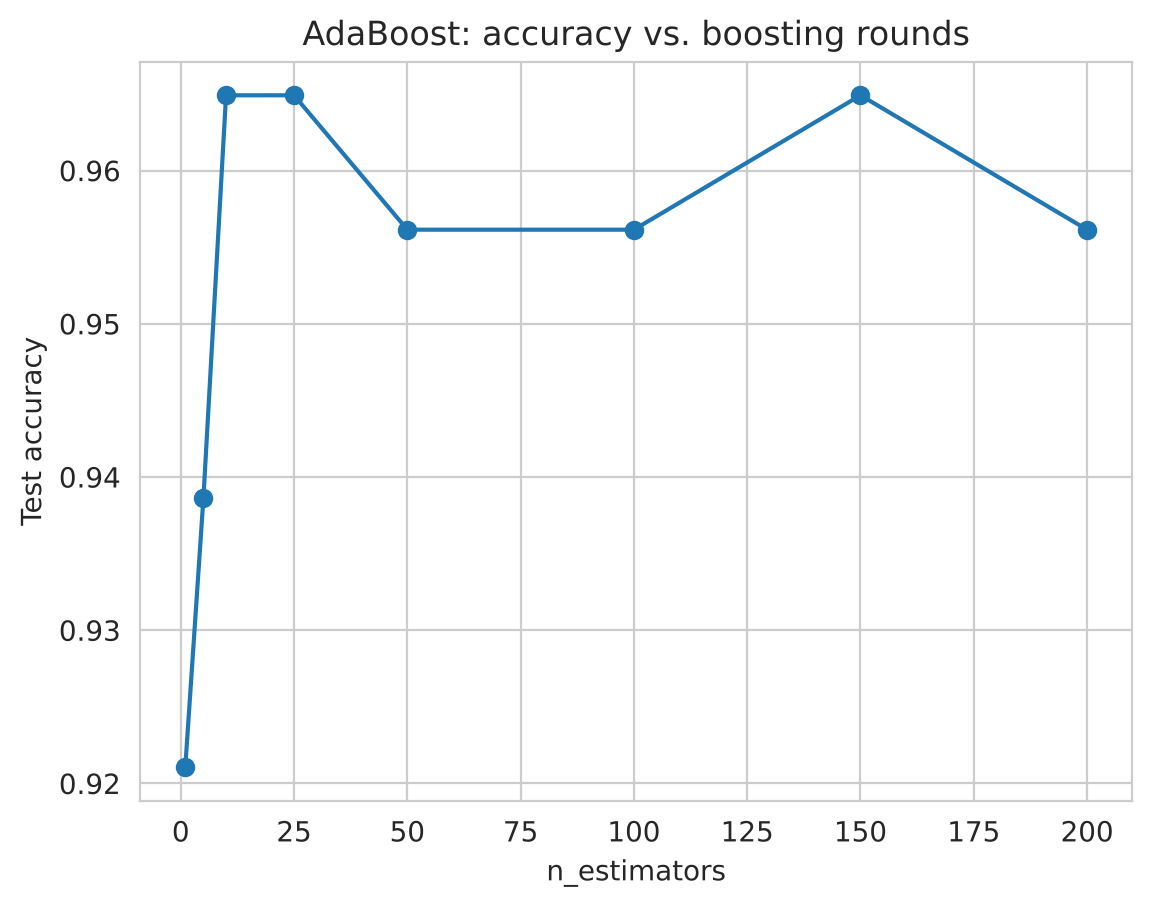

In [9]:
# Effect of the number of boosting rounds
n_range = [1, 5, 10, 25, 50, 100, 150, 200]
test_acc = [accuracy_score(y_test, AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1),
            n_estimators=n, learning_rate=0.5, random_state=RANDOM_STATE).fit(X_train, y_train).predict(X_test))
            for n in n_range]
plt.plot(n_range, test_acc, marker='o')
plt.xlabel('n_estimators'); plt.ylabel('Test accuracy'); plt.title('AdaBoost: accuracy vs. boosting rounds')
plt.show()

## 8. Performance Comparison
Metrics: Accuracy, Precision, Recall, F1-score, ROC-AUC (test set) and 5-fold cross-validated accuracy (mean ± std) for a more reliable comparison.

In [10]:
all_models = {**base_models(),
              'Voting (Hard)': VotingClassifier(estimators=list(base_models().items()), voting='hard'),
              'Voting (Soft)': VotingClassifier(estimators=list(base_models().items()), voting='soft'),
              'Stacking': StackingClassifier(estimators=list(base_models().items()),
                          final_estimator=LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), cv=5),
              'AdaBoost (stump)': AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1),
                          n_estimators=200, learning_rate=0.5, random_state=RANDOM_STATE),
              'AdaBoost (depth 3)': AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=3),
                          n_estimators=100, learning_rate=0.5, random_state=RANDOM_STATE)}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows, fitted, preds = [], {}, {}

for name, m in all_models.items():
    m.fit(X_train, y_train)
    y_pred = m.predict(X_test)
    # hard voting has no predict_proba -> use predictions for AUC
    y_score = m.predict_proba(X_test)[:, 1] if hasattr(m, 'predict_proba') else y_pred
    cv = cross_val_score(m, X, y, cv=skf, scoring='accuracy')
    rows.append({'Model': name,
                 'Accuracy':  accuracy_score(y_test, y_pred),
                 'Precision': precision_score(y_test, y_pred),
                 'Recall':    recall_score(y_test, y_pred),
                 'F1-score':  f1_score(y_test, y_pred),
                 'ROC-AUC':   roc_auc_score(y_test, y_score),
                 'CV Acc (mean)': cv.mean(), 'CV Acc (std)': cv.std()})
    fitted[name], preds[name] = m, (y_pred, y_score)

results = pd.DataFrame(rows).set_index('Model').round(4)
results.sort_values('F1-score', ascending=False)

,Accuracy,Precision,Recall,F1-score,ROC-AUC,CV Acc (mean),CV Acc (std)
Model,,,,,,,
Logistic Regression,0.9825,0.9861,0.9861,0.9861,0.9954,0.9737,0.0166
SVM (RBF),0.9825,0.9861,0.9861,0.9861,0.9950,0.9772,0.0163
KNN,0.9737,0.9600,1.0000,0.9796,0.9884,0.9649,0.0184
Voting (Soft),0.9737,0.9600,1.0000,0.9796,0.9927,0.9613,0.0131
Stacking,0.9737,0.9726,0.9861,0.9793,0.9944,0.9737,0.0096
Voting (Hard),0.9737,0.9726,0.9861,0.9793,0.9692,0.9736,0.0124
AdaBoost (depth 3),0.9649,0.9595,0.9861,0.9726,0.9911,0.9701,0.0131
AdaBoost (stump),0.9561,0.9467,0.9861,0.9660,0.9848,0.9613,0.0181
Naive Bayes,0.9386,0.9452,0.9583,0.9517,0.9878,0.9385,0.0235


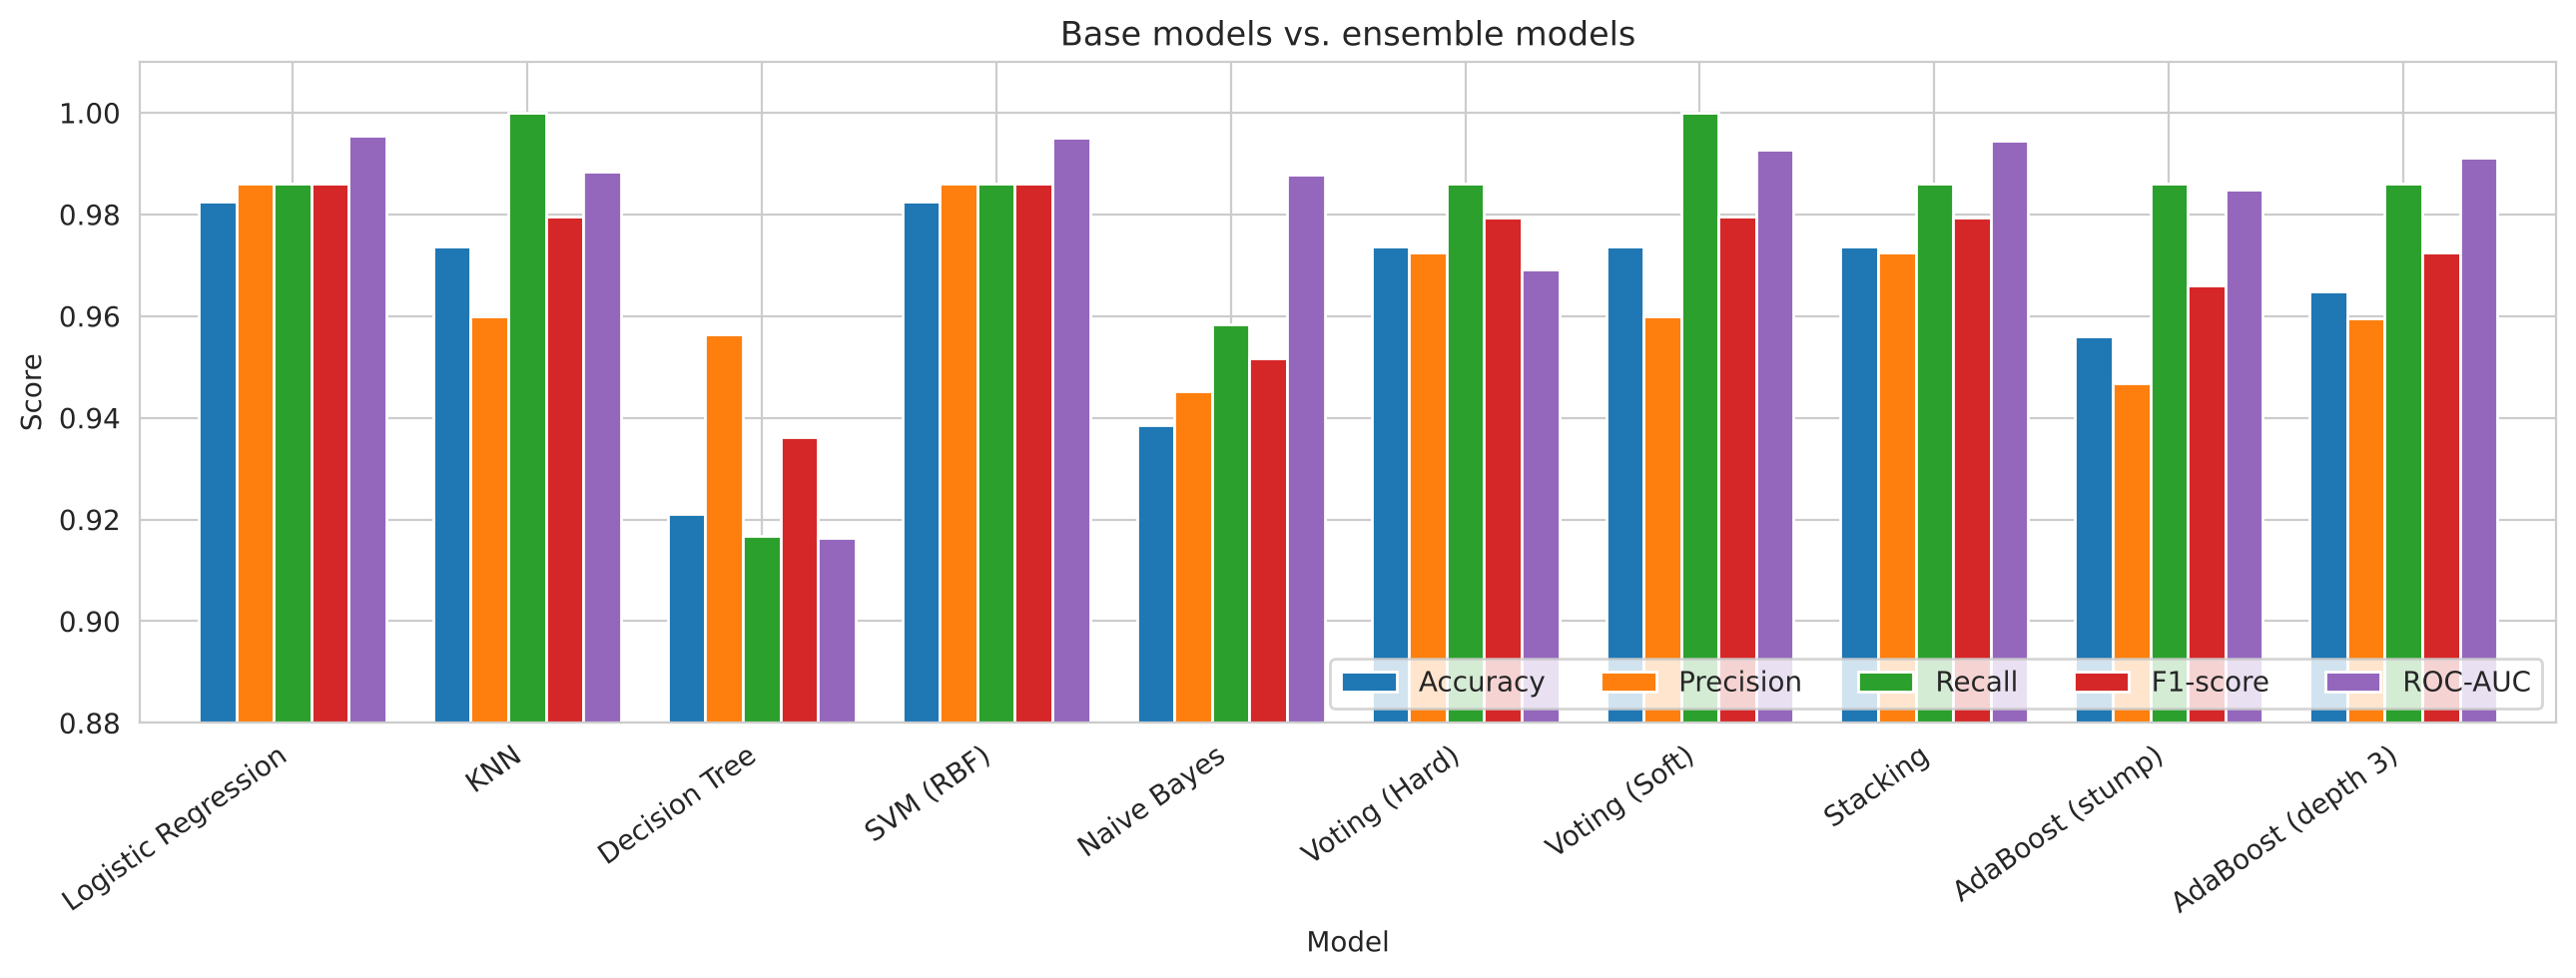

In [11]:
ax = results[['Accuracy','Precision','Recall','F1-score','ROC-AUC']].plot(kind='bar', figsize=(13,5), width=0.8)
ax.set_ylim(0.88, 1.01); plt.xticks(rotation=35, ha='right')
plt.title('Base models vs. ensemble models'); plt.ylabel('Score'); plt.legend(loc='lower right', ncol=5)
plt.tight_layout(); plt.show()

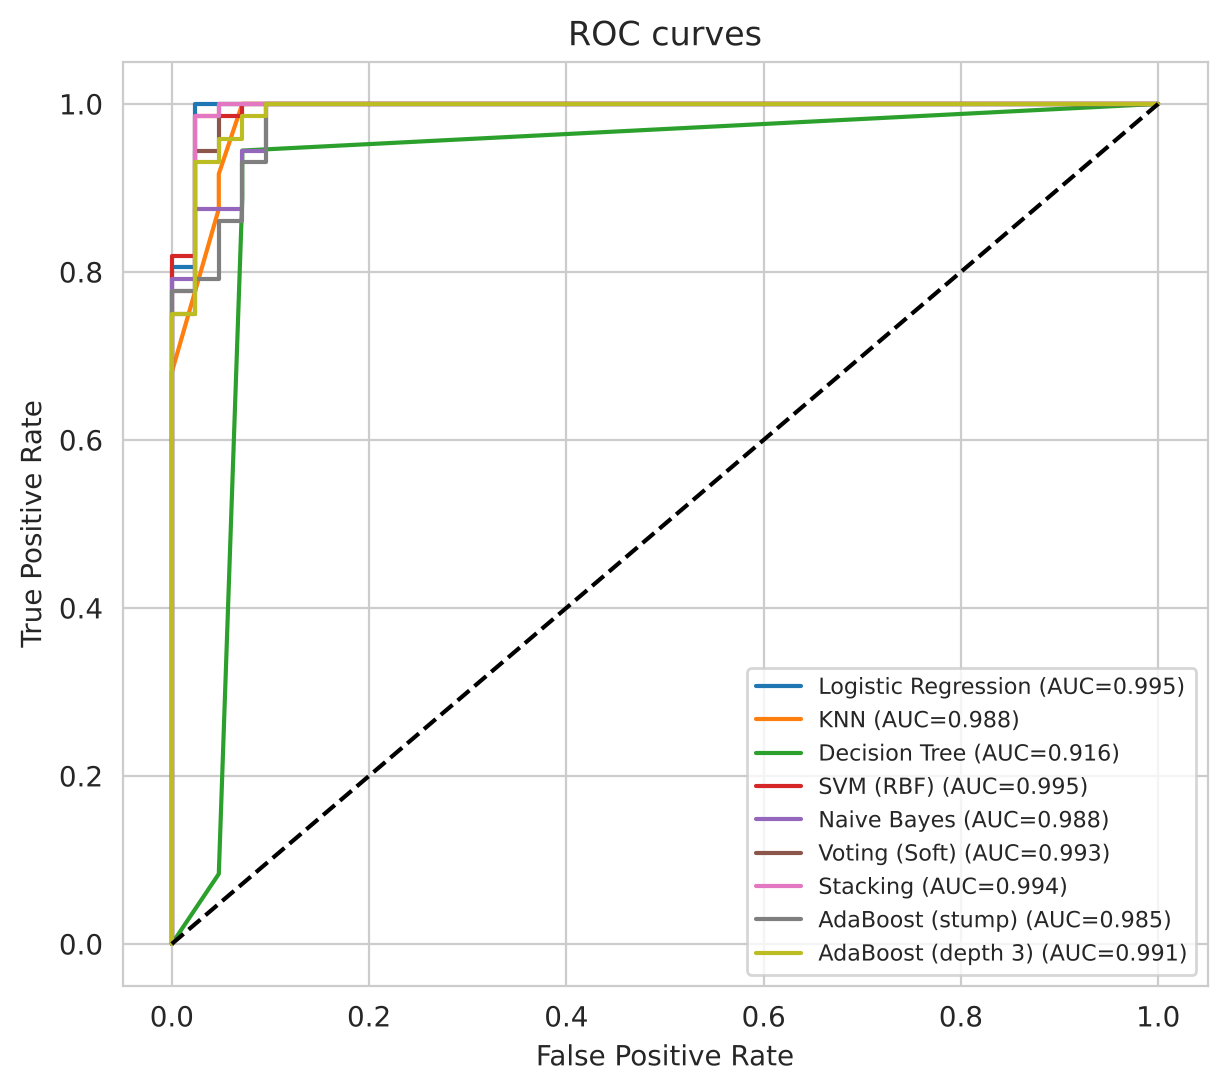

In [12]:
# ROC curves
plt.figure(figsize=(7,6))
for name,(yp,ys) in preds.items():
    if name == 'Voting (Hard)': continue
    fpr,tpr,_ = roc_curve(y_test, ys)
    plt.plot(fpr,tpr,label=f'{name} (AUC={roc_auc_score(y_test,ys):.3f})')
plt.plot([0,1],[0,1],'k--'); plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC curves'); plt.legend(fontsize=8); plt.show()

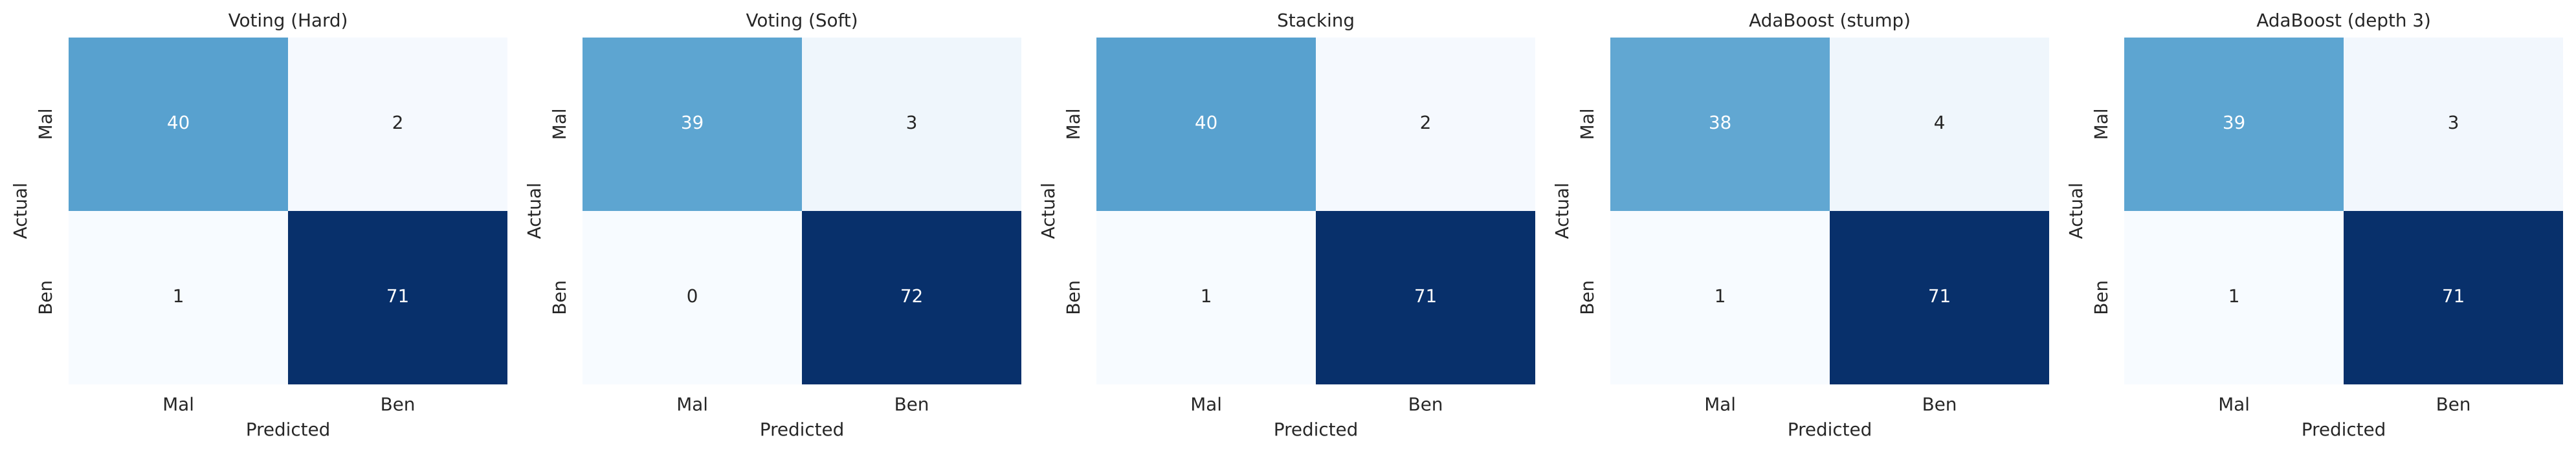

In [13]:
# Confusion matrices of ensemble models
ens = ['Voting (Hard)','Voting (Soft)','Stacking','AdaBoost (stump)','AdaBoost (depth 3)']
fig, axes = plt.subplots(1, 5, figsize=(20,3.6))
for ax, name in zip(axes, ens):
    sns.heatmap(confusion_matrix(y_test, preds[name][0]), annot=True, fmt='d', cmap='Blues',
                cbar=False, ax=ax, xticklabels=['Mal','Ben'], yticklabels=['Mal','Ben'])
    ax.set_title(name, fontsize=10); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
plt.tight_layout(); plt.show()

In [14]:
best = results['F1-score'].idxmax()
print('Best model by F1-score:', best)
print(classification_report(y_test, preds[best][0], target_names=data.target_names))

Best model by F1-score: Logistic Regression
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



In [15]:
# Do ensembles beat the best single base model?
base_names = list(base_models().keys())
best_base = results.loc[base_names, 'CV Acc (mean)'].idxmax()
print(f'Best base model (CV): {best_base} -> {results.loc[best_base,"CV Acc (mean)"]:.4f}')
for n in ens:
    print(f'{n:20s} CV acc = {results.loc[n,"CV Acc (mean)"]:.4f}  '
          f'(diff vs best base = {results.loc[n,"CV Acc (mean)"]-results.loc[best_base,"CV Acc (mean)"]:+.4f})')

Best base model (CV): SVM (RBF) -> 0.9772
Voting (Hard)        CV acc = 0.9736  (diff vs best base = -0.0036)
Voting (Soft)        CV acc = 0.9613  (diff vs best base = -0.0159)
Stacking             CV acc = 0.9737  (diff vs best base = -0.0035)
AdaBoost (stump)     CV acc = 0.9613  (diff vs best base = -0.0159)
AdaBoost (depth 3)   CV acc = 0.9701  (diff vs best base = -0.0071)


## 9. Summary of Findings

**Observations** (from my run, random_state=42)
- Logistic Regression and SVM were the best individual models (test accuracy 98.25%, F1 0.986). On this clean, small, well-scaled dataset a single strong model is already near the ceiling, so ensembles had little room to improve.
- Ensembles clearly **beat the weak base learners**: Decision Tree (92.1%) and Naive Bayes (93.9%) were lifted to 95.6-97.4% by AdaBoost, Voting and Stacking.
- **Hard Voting, Soft Voting and Stacking** reached 97.4% test accuracy, close to but slightly below the best single model. **Stacking** had the lowest CV standard deviation (0.0096), meaning the most stable results across folds. **AdaBoost with depth-3 trees** (96.5%) beat AdaBoost with stumps (95.6%).
- The ensembles' 5-fold CV accuracy (about 96.1-97.4%) was within about 1.6 points of the best base model (SVM, 97.7%), a difference that is within one standard deviation, so it is not significant.
- Takeaway: ensembles do not automatically beat the best single model; they mainly give **robustness and lower variance**, and they help most when the base models are weak or diverse.
- Recall for the malignant class matters most in a medical setting, since a missed malignant case is costlier than a false alarm. Check the confusion matrices for this.
- With only 114 test samples, one sample is about 0.9%, so cross-validation is more trustworthy than a single split.

**When to use each method**

| Method | Idea | Use when | Drawbacks |
|---|---|---|---|
| **Voting** | Combine diverse models by majority/average | You have several decent, *different* models and want a simple, robust boost with no extra training logic | Gains vanish if models make the same errors; weak models can drag it down |
| **Stacking** | Meta-model learns how to weigh base models | You want maximum accuracy, base models have complementary strengths, and you have enough data | Most expensive, more complex, risk of overfitting/leakage if CV is not used |
| **AdaBoost** | Sequential weak learners focus on hard samples | You have a weak/simple base learner (stumps) and want to reduce **bias**; moderate-size clean data | Sensitive to noise and outliers; sequential so not parallelisable |

**Further research / improvements**
- Tune hyperparameters (GridSearch/Optuna) for base learners, number of estimators and learning rate
- Try other boosting methods (Gradient Boosting, XGBoost, LightGBM) and bagging/Random Forest
- Use weighted voting and add more diverse base learners; try different meta-classifiers (Random Forest, Gradient Boosting)
- Test on larger, noisier, or imbalanced datasets (apply SMOTE / class weights, use PR-AUC)
- Add feature selection, probability calibration and model explainability (SHAP)
- Use repeated CV and statistical tests (e.g. McNemar, paired t-test) to confirm differences are significant

**Conclusion:** Ensemble learning generally improves robustness and generalisation over individual models; the best method depends on the data, the cost of errors, and the available compute.

---
*Submitted by Yash Galande | 202401040179 | A2 – 41*